# import data

In [25]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import KFold, GroupKFold, cross_val_predict, train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

from clean_zenodo import bersihkan

pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
plt.rcParams["figure.figsize"] = (8, 4)

PATH_DATA = "../data/dataset_raw_29747.csv"
PATH_MODEL = "../models/model_v2.joblib"

In [26]:
df, laporan = bersihkan(PATH_DATA)
for k, v in laporan.items():
    print(f"{k:35s} {v:>7,}")
print("\nUkuran data bersih:", df.shape)
df.head()

baris_awal                           29,747
setelah_buang_kosong_dan_header      29,569
setelah_harga_tahun_valid            28,797
setelah_hapus_url_ganda              25,494
setelah_hapus_iklan_kembar           18,885
baris_akhir                          18,885

Ukuran data bersih: (18885, 15)


,sumber,batch,merek,model,varian,tahun,km,transmisi,bahan_bakar,mesin_l,bodi,kota,tgl,bulan_idx,harga
0,OLX,B1-2025,Mercedes-Benz,A-Class,2.0 Bensin-AT,2014,NaN,Automatic,Bensin,2.0,Hatchback,Jakarta Timur,2025-10-07,10.0,"499,000,000.0"
1,OLX,B1-2025,Mercedes-Benz,Sprinter,NaN,2021,NaN,Manual,Diesel,NaN,Tidak diketahui,Jakarta Utara,2025-10-17,10.0,"1,850,000,000.0"
2,OLX,B1-2025,Mercedes-Benz,GLC-Class,2.0 AMG Line Bensin-AT,2022,NaN,Automatic,Bensin,2.0,SUV,Jakarta Barat,2025-10-06,10.0,"720,000,000.0"
3,OLX,B1-2025,Mercedes-Benz,GLE-Class,3.0 Coupe AMG Line Bensin-AT,2016,NaN,Automatic,Bensin,3.0,SUV,Jakarta Selatan,2025-10-10,10.0,"598,000,000.0"
4,OLX,B1-2025,Mercedes-Benz,Lainnya,Lain-lain-AT,2010,NaN,Automatic,Bensin,NaN,Tidak diketahui,Denpasar Kota,2025-10-23,10.0,"159,000,000.0"


# EDA

In [27]:
print("Merek:")
print(df["merek"].value_counts().to_string())
print("\nKelengkapan kolom (bagian yang terisi):")
print(df[["km", "mesin_l", "transmisi", "bahan_bakar", "bodi"]].notna().mean().round(3).to_string())
print("\nKilometer terisi per batch:")
print(df.groupby("batch")["km"].apply(lambda s: s.notna().mean()).round(3).to_string())

Merek:
merek
Honda            4749
Toyota           3640
Daihatsu         3498
Mercedes-Benz    2998
Suzuki           2914
Mitsubishi        439
Wuling            409
BYD               226
Denza               4
Hyundai             2
BMW                 1
Chery               1
MINI                1
Mazda               1
DFSK                1
Smart               1

Kelengkapan kolom (bagian yang terisi):
km            0.5
mesin_l       1.0
transmisi     1.0
bahan_bakar   1.0
bodi          1.0

Kilometer terisi per batch:
batch
B1-2025   0.8
B2-2026   0.2


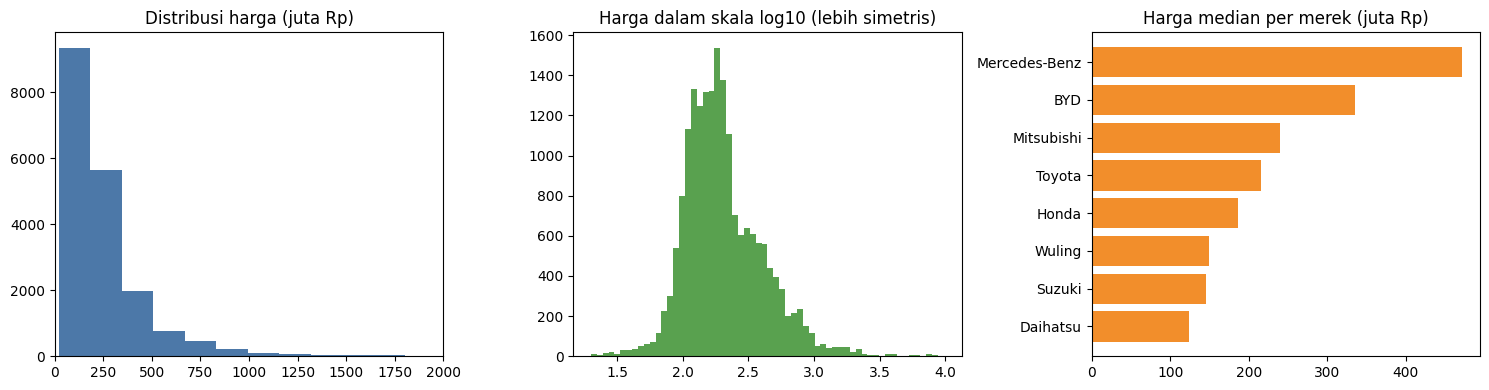

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].hist(df["harga"] / 1e6, bins=60, color="#4c78a8")
ax[0].set_title("Distribusi harga (juta Rp)")
ax[0].set_xlim(0, 2000)

ax[1].hist(np.log10(df["harga"] / 1e6), bins=60, color="#59a14f")
ax[1].set_title("Harga dalam skala log10 (lebih simetris)")

med = df.groupby("merek")["harga"].median().sort_values() / 1e6
med = med[df["merek"].value_counts()[med.index] >= 50]
ax[2].barh(med.index, med.values, color="#f28e2b")
ax[2].set_title("Harga median per merek (juta Rp)")

plt.tight_layout()
plt.show()

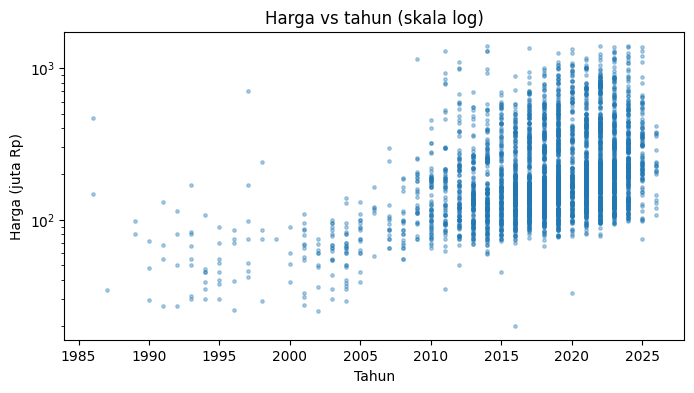

Median harga per kelompok bahan bakar (juta Rp):
bahan_bakar
Bensin    175.0
Diesel    375.0
Hybrid    280.0
Listrik   280.0


In [29]:
sampel = df[df["harga"] < 1.5e9].sample(4000, random_state=0)
plt.figure(figsize=(8, 4))
plt.scatter(sampel["tahun"], sampel["harga"] / 1e6, s=6, alpha=0.35)
plt.yscale("log")
plt.title("Harga vs tahun (skala log)")
plt.xlabel("Tahun")
plt.ylabel("Harga (juta Rp)")
plt.show()

print("Median harga per kelompok bahan bakar (juta Rp):")
print((df.groupby("bahan_bakar")["harga"].median() / 1e6).round(0).to_string())

# Fitur
#####
- `umur` = 2026 dikurangi tahun mobil.
- `model_g` = merek + model. Model dengan data sedikit (< 8 iklan) digabung jadi `"<merek> LAINNYA"` supaya model tidak menghafal.
- Model dilatih pada **semua iklan**, termasuk yang km-nya kosong (pohon keputusan bisa menangani nilai kosong). Kalau hanya iklan ber-km yang dipakai, Mitsubishi, Wuling, dan BYD hampir hilang dari data karena batch 2026 jarang mencantumkan km.
- Karena app meminta km dari penjual, hasil dilaporkan **dua kali**: semua iklan, dan hanya iklan yang km-nya diketahui (situasi app yang sebenarnya).
- Merek dengan kurang dari 50 iklan dikeluarkan dan app akan menolaknya dengan jujur.

In [30]:
TAHUN_ACUAN = 2026
MIN_MEREK = 50      
MIN_MODEL = 8 
      
data = df[df["bahan_bakar"].notna()].copy()
jumlah_merek = data["merek"].value_counts()
MEREK_DIDUKUNG = sorted(jumlah_merek[jumlah_merek >= MIN_MEREK].index)
data = data[data["merek"].isin(MEREK_DIDUKUNG)].copy()
ADA_KM = data["km"].notna().values   # penanda: iklan yang km-nya diketahui

data["umur"] = (TAHUN_ACUAN - data["tahun"]).clip(lower=0)
data["model_lengkap"] = data["merek"] + " " + data["model"].astype(str)
jumlah_model = data["model_lengkap"].value_counts()
MODEL_DIKENAL = set(jumlah_model[jumlah_model >= MIN_MODEL].index)
data["model_g"] = np.where(data["model_lengkap"].isin(MODEL_DIKENAL),
                           data["model_lengkap"], data["merek"] + " LAINNYA")

FITUR_KAT = ["merek", "model_g", "bahan_bakar", "bodi", "transmisi"]
FITUR_NUM = ["umur", "km", "mesin_l"]
X = data[FITUR_KAT + FITUR_NUM]
y = data["harga"]

print("Baris untuk model:", len(data), "| yang km-nya diketahui:", int(ADA_KM.sum()))
print("Merek didukung:", MEREK_DIDUKUNG)
print("Model dikenal (>= %d iklan): %d" % (MIN_MODEL, len(MODEL_DIKENAL)))

Baris untuk model: 18872 | yang km-nya diketahui: 9710
Merek didukung: ['BYD', 'Daihatsu', 'Honda', 'Mercedes-Benz', 'Mitsubishi', 'Suzuki', 'Toyota', 'Wuling']
Model dikenal (>= 8 iklan): 123


# Fungsi bantu bangun model

In [31]:
def model_pohon(kat, loss="squared_error", quantile=None):
    pre = ColumnTransformer(
        [("kat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), kat)],
        remainder="passthrough")
    reg = HistGradientBoostingRegressor(
        loss=loss, quantile=quantile, max_iter=400, learning_rate=0.06,
        categorical_features=list(range(len(kat))), random_state=0)
    return TransformedTargetRegressor(Pipeline([("pre", pre), ("reg", reg)]),
                                      func=np.log, inverse_func=np.exp)


def model_ridge(kat, num):
    pre = ColumnTransformer([
        ("kat", OneHotEncoder(handle_unknown="ignore"), kat),
        ("num", Pipeline([("isi", SimpleImputer(strategy="median")), ("skala", StandardScaler())]), num)])
    return TransformedTargetRegressor(Pipeline([("pre", pre), ("reg", Ridge(alpha=3.0))]),
                                      func=np.log, inverse_func=np.exp)


def skor(asli, pred):
    ape = np.abs(pred - asli) / asli
    return {"MAE (juta Rp)": np.mean(np.abs(pred - asli)) / 1e6,
            "MAPE (%)": ape.mean() * 100,
            "Median error (%)": np.median(ape) * 100}

# Bandingkan antar model 

In [32]:
kf = KFold(n_splits=5, shuffle=True, random_state=0)
kandidat = {
    "Tebak median (pembanding)": DummyRegressor(strategy="median"),
    "Ridge (linear)": model_ridge(FITUR_KAT, FITUR_NUM),
    "Gradient Boosting (pohon)": model_pohon(FITUR_KAT),
}
hasil, pred_cv = {}, {}
for nama, m in kandidat.items():
    pred_cv[nama] = cross_val_predict(m, X, y, cv=kf)
    hasil[nama] = skor(y.values, pred_cv[nama])
tabel_a = pd.DataFrame(hasil).T
print("Semua iklan:")
display(tabel_a)
print("Hanya iklan yang km-nya diketahui (situasi di app):")
pd.DataFrame({n: skor(y.values[ADA_KM], p[ADA_KM]) for n, p in pred_cv.items()}).T

Semua iklan:


,MAE (juta Rp),MAPE (%),Median error (%)
Tebak median (pembanding),150.3,49.9,41.3
Ridge (linear),48.2,14.6,9.6
Gradient Boosting (pohon),31.8,10.3,6.6


Hanya iklan yang km-nya diketahui (situasi di app):


,MAE (juta Rp),MAPE (%),Median error (%)
Tebak median (pembanding),118.2,40.8,35.3
Ridge (linear),35.6,11.9,8.8
Gradient Boosting (pohon),22.4,8.0,5.8


# Uji

In [33]:
kat_tanpa_model = [k for k in FITUR_KAT if k != "model_g"]
m_baru = model_pohon(kat_tanpa_model)
pred_baru = cross_val_predict(m_baru, X[kat_tanpa_model + FITUR_NUM], y,
                              cv=GroupKFold(n_splits=5), groups=data["model_g"])
p_dikenal = pred_cv["Gradient Boosting (pohon)"]
skor_baru = skor(y.values, pred_baru)

tabel_b = pd.DataFrame({
    "Model dikenal, km diketahui": skor(y.values[ADA_KM], p_dikenal[ADA_KM]),
    "Model dikenal, semua iklan": skor(y.values, p_dikenal),
    "Model baru, km diketahui": skor(y.values[ADA_KM], pred_baru[ADA_KM]),
    "Model baru, semua iklan": skor_baru,
}).T
tabel_b

,MAE (juta Rp),MAPE (%),Median error (%)
"Model dikenal, km diketahui",22.4,8.0,5.8
"Model dikenal, semua iklan",31.8,10.3,6.6
"Model baru, km diketahui",62.8,19.6,13.9
"Model baru, semua iklan",81.4,23.3,16.1


In [34]:
# Seberapa meleset per merek dan per rentang harga (skenario model dikenal)
cek = data[["merek", "harga"]].copy()
cek["error_%"] = np.abs(pred_cv["Gradient Boosting (pohon)"] - y.values) / y.values * 100
cek["pita_harga"] = pd.cut(cek["harga"] / 1e6, [0, 150, 300, 600, 1000, 1e6],
                           labels=["< 150 jt", "150-300 jt", "300-600 jt", "600 jt - 1 M", "> 1 M"])
print("Rata-rata error (%) per merek:")
print(cek.groupby("merek")["error_%"].agg(jumlah="size", MAPE="mean").sort_values("jumlah", ascending=False).to_string())
print("\nRata-rata error (%) per rentang harga:")
print(cek.groupby("pita_harga")["error_%"].agg(jumlah="size", MAPE="mean").to_string())

Rata-rata error (%) per merek:
               jumlah  MAPE
merek                      
Honda            4749   8.3
Toyota           3640   9.5
Daihatsu         3498   8.4
Mercedes-Benz    2997  17.1
Suzuki           2914   9.5
Mitsubishi        439  12.8
Wuling            409  11.1
BYD               226   6.4

Rata-rata error (%) per rentang harga:
              jumlah  MAPE
pita_harga                
< 150 jt        6817  11.7
150-300 jt      7410   8.4
300-600 jt      3311  10.3
600 jt - 1 M     917  12.5
> 1 M            417  15.8


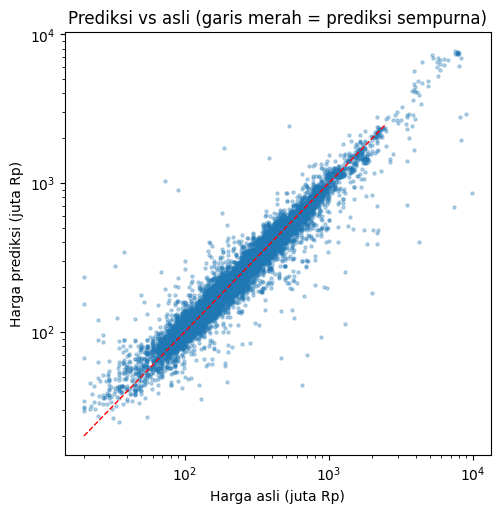

In [35]:
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y / 1e6, pred_cv["Gradient Boosting (pohon)"] / 1e6, s=5, alpha=0.3)
batas = [20, 2500]
plt.plot(batas, batas, "r--", lw=1)
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Harga asli (juta Rp)"); plt.ylabel("Harga prediksi (juta Rp)")
plt.title("Prediksi vs asli (garis merah = prediksi sempurna)")
plt.show()